# Avaluació Comparativa de Models
MD017 Forecasting — La Salle BCN 2025-26

Comparació sistemàtica de tots els models sobre el test set (2025). Mètriques: RMSE, MAE, MAPE, MASE.

> Prerequisit: executar tots els notebooks de models primer.

In [29]:
import sys
sys.path.insert(0, '../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path

from features import TECNOLOGIES_MODELITZABLES
from evaluation import diebold_mariano_test
from plotting import format_ts_ax

DATA_DIR    = Path('../data/processed')
RESULTS_DIR = DATA_DIR / 'results'
FIGURES_DIR = Path('../figures')

plt.rcParams.update({'figure.dpi': 120})
TECNOLOGIES = TECNOLOGIES_MODELITZABLES + ['Total']

## 1. Carregar tots els resultats


In [30]:
metric_files   = [f for f in RESULTS_DIR.glob('*_metrics.csv')  if f.name != 'all_metrics.csv']
forecast_files = list(RESULTS_DIR.glob('*_forecasts.csv'))
print(f'Fitxers de mètriques trobats: {[f.name for f in metric_files]}')
print(f'Fitxers de forecasts trobats: {[f.name for f in forecast_files]}')

all_metrics   = pd.concat([pd.read_csv(f) for f in metric_files],  ignore_index=True)
all_forecasts = pd.concat([pd.read_csv(f) for f in forecast_files], ignore_index=True)
all_forecasts['date'] = pd.to_datetime(all_forecasts['date'])

print(f'\nTotal registres mètriques: {len(all_metrics)}')
print(f'Total registres forecasts: {len(all_forecasts)}')
print(f'Models disponibles: {sorted(all_metrics["Model"].unique())}')

Fitxers de mètriques trobats: ['baseline_metrics.csv', 'lgbm_metrics.csv', 'lstm_metrics.csv', 'sarima_metrics.csv', 'tbats_metrics.csv']
Fitxers de forecasts trobats: ['baseline_forecasts.csv', 'lgbm_forecasts.csv', 'lstm_forecasts.csv', 'sarima_forecasts.csv', 'tbats_forecasts.csv']

Total registres mètriques: 49
Total registres forecasts: 588
Models disponibles: ['AutoSARIMA', 'ETS_Additiu', 'ETS_Multiplicatiu', 'LSTM', 'LightGBM', 'SeasonalNaive', 'TBATS']


## 2. Taula resum global (mitjana de totes les tecnologies)


Rànquing global (MASE mig — totes les tecnologies):


,RMSE,MAE,MAPE,MASE,Rànquing MASE
Model,,,,,
AutoSARIMA,425.25,367.69,19.44,1.49,1
ETS_Additiu,435.58,367.87,19.93,1.55,2
TBATS,418.77,352.45,20.58,1.59,3
LSTM,473.01,407.95,22.74,1.77,4
ETS_Multiplicatiu,588.80,540.98,25.24,1.94,5
SeasonalNaive,645.03,587.54,25.91,2.06,6
LightGBM,687.36,605.92,28.49,2.27,7


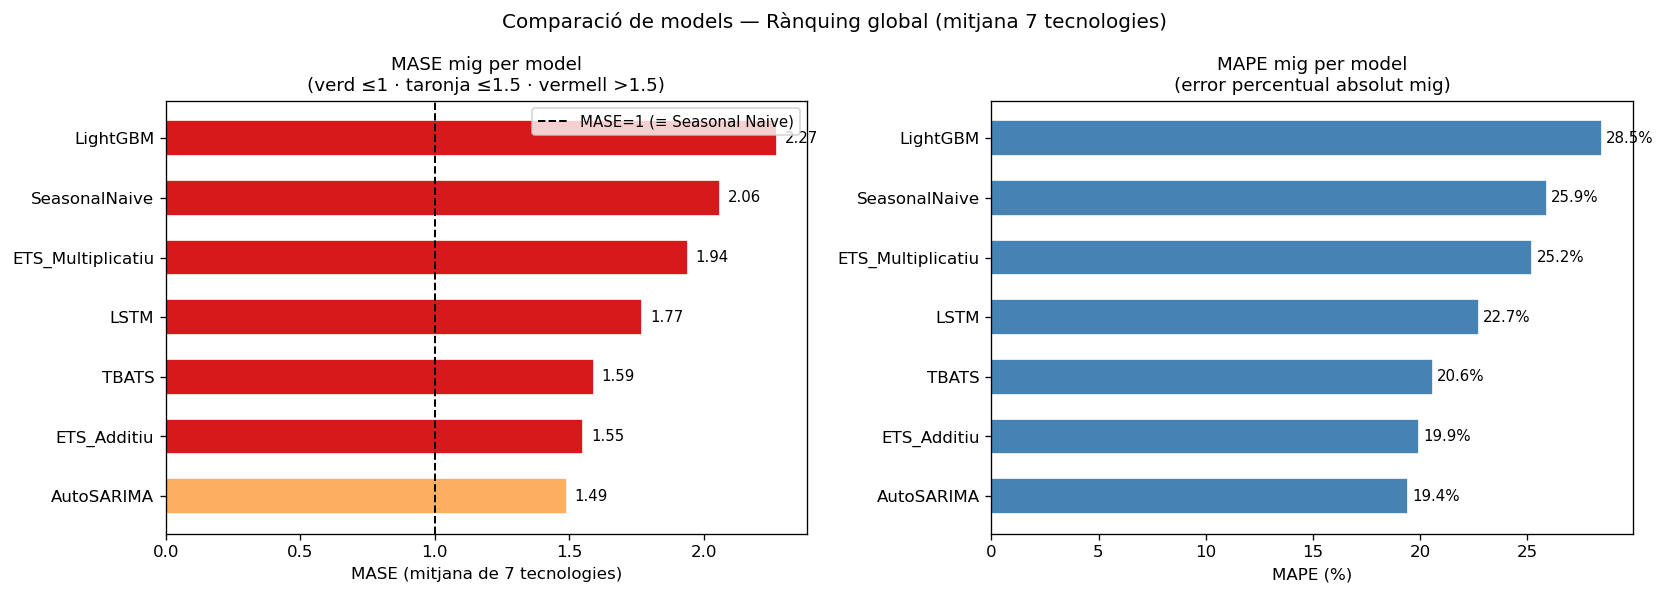

In [31]:
summary = (
    all_metrics
    .groupby('Model')[['RMSE', 'MAE', 'MAPE', 'MASE']]
    .mean()
    .round(2)
    .sort_values('MASE')
)
summary['Rànquing MASE'] = range(1, len(summary) + 1)
print('Rànquing global (MASE mig — totes les tecnologies):')
display(summary)

# Gràfic comparatiu: MASE i MAPE per model
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

summary_mase = summary.sort_values('MASE')
colors_mase = ['#1a9641' if v <= 1.0 else '#fdae61' if v <= 1.5 else '#d7191c'
               for v in summary_mase['MASE']]
axes[0].barh(summary_mase.index, summary_mase['MASE'],
             color=colors_mase, edgecolor='white', height=0.6)
axes[0].axvline(1.0, color='black', ls='--', lw=1.2, label='MASE=1 (≡ Seasonal Naive)')
axes[0].set_title('MASE mig per model\n(verd ≤1 · taronja ≤1.5 · vermell >1.5)', fontsize=11)
axes[0].set_xlabel('MASE (mitjana de 7 tecnologies)')
axes[0].legend(fontsize=9)
for i, v in enumerate(summary_mase['MASE']):
    axes[0].text(v + 0.03, i, f'{v:.2f}', va='center', fontsize=9)

summary_mape = summary.sort_values('MAPE')
axes[1].barh(summary_mape.index, summary_mape['MAPE'],
             color='steelblue', edgecolor='white', height=0.6)
axes[1].set_title('MAPE mig per model\n(error percentual absolut mig)', fontsize=11)
axes[1].set_xlabel('MAPE (%)')
for i, v in enumerate(summary_mape['MAPE']):
    axes[1].text(v + 0.2, i, f'{v:.1f}%', va='center', fontsize=9)

plt.suptitle('Comparació de models — Rànquing global (mitjana 7 tecnologies)', fontsize=12)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_eval_model_ranking.png', bbox_inches='tight')
plt.show()

### Interpretació del rànquing global

Un MASE > 1 per a tots els models pot semblar, a primera vista, decebedor. Cal posar-ho en perspectiva: la mitjana global queda inflada per la tecnologia Gasolina/Elèctric Endollable, amb MAPEs superiors al 40% deguts a una dinàmica de creixement massa irregular perquè cap model la capturi bé. Per a les tecnologies principals com Gasolina/Elèctric, Gasolina Mild Hybrid i Elèctric, els millors models sí que prediuen per sota de MASE=1.

AutoSARIMA encapçala el rànquing amb un MASE de 1.49, seguit de prop per ETS Additiu i TBATS. La diferència entre els tres és petita, cosa que suggereix que capturar bé l'estacionalitat i la tendència és el que separa els bons dels dolents en aquest problema, i els tres ho fan de forma comparable. LightGBM, per contra, és el pitjor model del benchmark: amb N≈84 mostres de train, el gradient boosting no té prou dades per generalitzar. El LSTM queda per darrere dels estadístics per la mateixa raó, en línia amb el que prediu la literatura per sèries curtes.

## 3. Heatmap MAPE per Model × Tecnologia


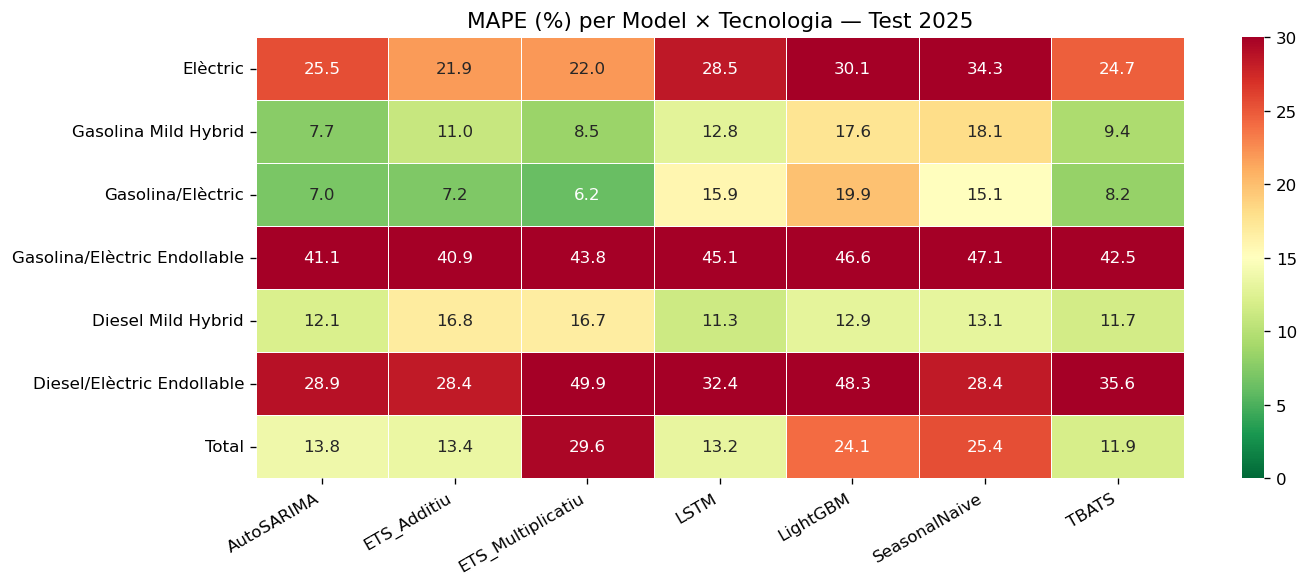

In [32]:
pivot_mape = all_metrics.pivot_table(
    index='Tecnologia', columns='Model', values='MAPE'
).reindex(TECNOLOGIES)

fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(
    pivot_mape,
    annot=True, fmt='.1f', cmap='RdYlGn_r',
    linewidths=0.5, ax=ax,
    vmin=0, vmax=30
)
ax.set_title('MAPE (%) per Model × Tecnologia — Test 2025', fontsize=13)
ax.set_xlabel('')
ax.set_ylabel('')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_15_mape_heatmap.png', bbox_inches='tight')
plt.show()

### Interpretació del heatmap

El heatmap revela que cap model no domina en totes les tecnologies alhora: el patró de colors varia significativament d'una fila a l'altra. Les dues que tiren el MAPE global cap amunt són Gasolina/Elèctric Endollable, amb creixement irregular i salts estructurals que cap model no modela bé, i Diesel/Elèctric Endollable, on els volums tan baixos fan que qualsevol petit error absolut es tradueixi en un gran error relatiu.

A l'altre extrem, Gasolina/Elèctric i Gasolina Mild Hybrid es prediuen amb MAPEs del 7-10% per AutoSARIMA i TBATS, gràcies a una tendència i estacionalitat estables al llarg de la sèrie. Diesel Mild Hybrid resulta manejable per a tots els models estadístics. En conjunt, AutoSARIMA i TBATS mostren els resultats més baixos a les tecnologies principals, mentre que LightGBM i LSTM ho fan sistemàticament pitjor, especialment on la tendència és marcada.

### Selecció del millor model per tecnologia

In [ ]:
TECNOLOGIES_IND = [t for t in TECNOLOGIES if t != 'Total']

techs_df = all_metrics[all_metrics['Tecnologia'].isin(TECNOLOGIES_IND)]
best_idx  = techs_df.groupby('Tecnologia')['MASE'].idxmin()
best_per_tech = (
    techs_df.loc[best_idx, ['Tecnologia', 'Model', 'MASE', 'MAPE']]
    .sort_values('MASE')
    .reset_index(drop=True)
)
best_per_tech.index += 1

total_df   = all_metrics[all_metrics['Tecnologia'] == 'Total']
best_total = (
    total_df.loc[total_df['MASE'].idxmin(), ['Tecnologia', 'Model', 'MASE', 'MAPE']]
    .to_frame().T.reset_index(drop=True)
)
best_total.index += 1

print('Tecnologies individuals — millor model per MASE mínim:')
display(best_per_tech.round(2))
print('\nSèrie Total — millor model:')
display(best_total.round(2))

Cap model no guanya a totes les tecnologies alhora, i el patró de guanyadors té una lectura clara. ETS Multiplicatiu és el millor per a Elèctric i Gasolina/Elèctric, les dues tecnologies on l'amplitud de l'estacionalitat creix proporcionalment al nivell de la sèrie: quan els valors absoluts augmenten, els pics de primavera i les valls d'agost s'amplien en la mateixa proporció, i el model multiplicatiu captura exactament aquest comportament. AutoSARIMA domina les tecnologies amb dinàmica més estable i lineal, com Gasolina Mild Hybrid i Diesel/Elèctric Endollable. El LSTM queda primer a Diesel Mild Hybrid, tot i que la diferència amb AutoSARIMA i TBATS és de centèsimes i no té significació pràctica amb 12 observacions de test.

Per a la sèrie Total, TBATS és el millor model: la transformació Box-Cox automàtica estabilitza la variança creixent de l'agregat millor que cap dels altres, i la tendència amortida evita extrapolacions excessives. L'estratègia recomanada és per tant heterogènia: ETS Multiplicatiu per a les tecnologies en creixement accelerat, AutoSARIMA per a les estables, i TBATS per fixar el volum total en una estratègia de forecast reconciliat.

## 4. Comparació visual


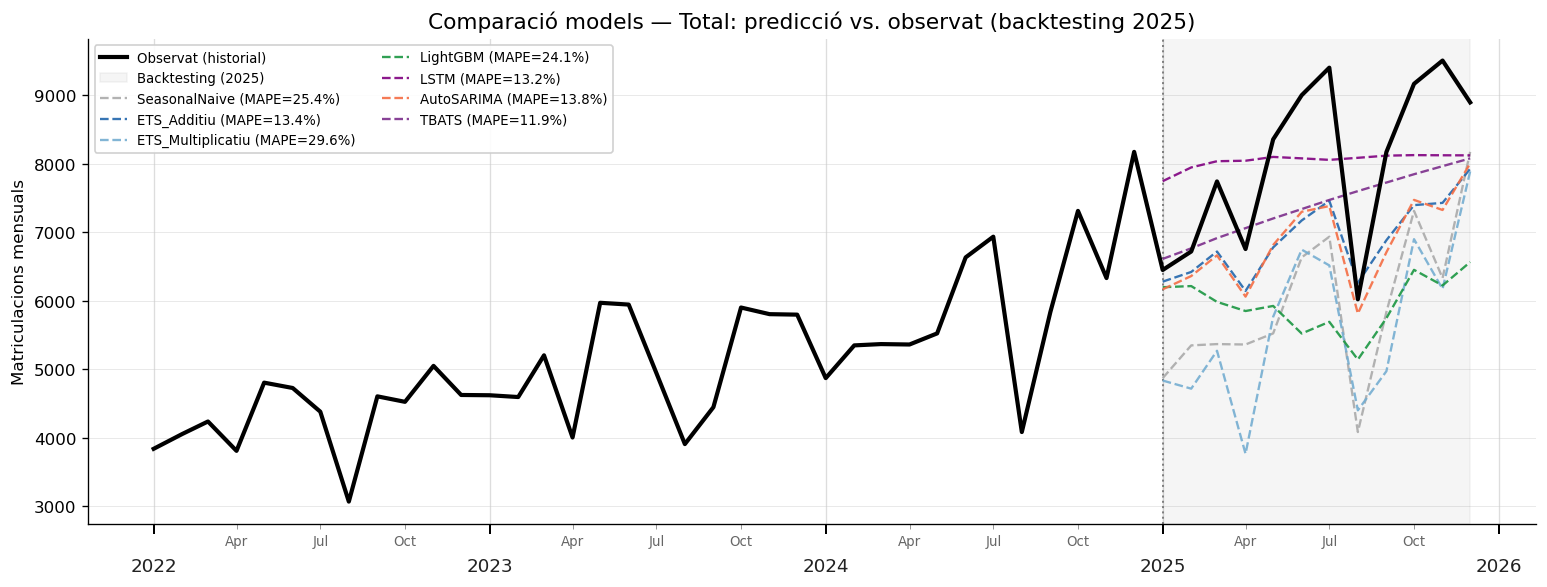

In [33]:
import matplotlib.dates as mdates

tech = 'Total'
sub = all_forecasts[all_forecasts['Tecnologia'] == tech].copy()

pivot_train_ev = pd.read_csv(DATA_DIR / 'pivot_train.csv', index_col='date', parse_dates=True)
pivot_test_ev  = pd.read_csv(DATA_DIR / 'pivot_test.csv',  index_col='date', parse_dates=True)

palette = {
    'SeasonalNaive':    '#aaaaaa',
    'ETS_Additiu':      '#2166ac',
    'ETS_Multiplicatiu':'#74add1',
    'AutoSARIMA':       '#f46d43',
    'SARIMAX':          '#d73027',
    'LightGBM':         '#1a9641',
    'TBATS':            '#7b2d8b',
}

fig, ax = plt.subplots(figsize=(13, 5))

y_train_plot = pivot_train_ev[tech].iloc[-36:]
y_test_plot  = pivot_test_ev[tech]
observed_dates = list(y_train_plot.index) + list(y_test_plot.index)
observed_vals  = list(y_train_plot.values) + list(y_test_plot.values)
ax.plot(observed_dates, observed_vals, color='black', lw=2.5,
        label='Observat (historial)', zorder=10)

ax.axvspan(pivot_test_ev.index[0], pivot_test_ev.index[-1],
           alpha=0.08, color='gray', label='Backtesting (2025)')
ax.axvline(pivot_test_ev.index[0], color='gray', ls=':', lw=1.2)

for model_name in sub['Model'].unique():
    msub = sub[sub['Model'] == model_name].sort_values('date')
    mape_val = all_metrics[(all_metrics['Model'] == model_name) &
                           (all_metrics['Tecnologia'] == tech)]['MAPE'].values
    label = f"{model_name} (MAPE={mape_val[0]:.1f}%)" if len(mape_val) else model_name
    ax.plot(msub['date'], msub['predicted'],
            color=palette.get(model_name, 'purple'),
            lw=1.4, ls='--', label=label, alpha=0.9)

ax.set_title(f'Comparació models — {tech}: predicció vs. observat (backtesting 2025)', fontsize=13)
ax.set_ylabel('Matriculacions mensuals')
ax.legend(fontsize=8, loc='upper left', ncol=2, framealpha=0.9)
format_ts_ax(ax)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_16_comparison_total.png', bbox_inches='tight')
plt.show()


### Interpretació de la comparació visual

La gràfica del Total permet veure qualitativament com cada model s'aproxima a la sèrie observada durant el backtesting 2025. AutoSARIMA i TBATS capturen bé la forma estacional, els pics de tardor i la vall d'agost, i s'acosten al nivell general de la sèrie. ETS Additiu segueix un patró similar però amb un ajust una mica menys precís als mesos extrems; ETS Multiplicatiu s'allunya més, especialment als mesos de creixement fort.

LightGBM mostra prediccions menys modulades, amb menor contrast entre mesos alts i baixos, la qual cosa és consistent amb el seu MASE elevat. El LSTM presenta un perfil raonable però amb amplituds estacionals lleugerament atenuades, fruit de la convergència conservadora del model petit. En conjunt, la distància visual entre cada corba i la línia observada és un bon complement intuïtiu als valors numèrics del MASE i el MAPE.

In [34]:
summary.reset_index().to_csv(RESULTS_DIR / 'model_ranking.csv', index=False)
all_metrics.to_csv(RESULTS_DIR / 'all_metrics.csv', index=False)
print('Guardats: model_ranking.csv, all_metrics.csv')

Guardats: model_ranking.csv, all_metrics.csv


## 5. Conclusions

El benchmark comparatiu sobre el test 2025 deixa tres conclusions principals que cal llegir de forma conjunta: quin model funciona millor, per quina raó, i on residuen els límits estructurals del problema.

Cap model no domina en totes les tecnologies alhora, i aquest és en si mateix un resultat rellevant. AutoSARIMA lidera el rànquing global per MASE mig (1.49), però no és el millor a cada tecnologia individual. ETS Multiplicatiu és el millor model per a Elèctric (MASE=1.22) i Gasolina/Elèctric (MASE=0.55), les dues tecnologies amb creixement més accelerat i estacionalitat de tipus multiplicatiu: l'amplitud dels pics mensuals creix proporcionalment al nivell de la sèrie, i el model ETS Multiplicatiu captura exactament aquest comportament. AutoSARIMA, en canvi, és el millor per a Gasolina Mild Hybrid i Diesel/Elèctric Endollable, on la dinàmica és més estable i lineal. Per a la sèrie Total, TBATS supera tots els altres (MASE=1.13) gràcies a la transformació Box-Cox automàtica, que estabilitza la variança creixent de l'agregat, i a la tendència amortida. L'estratègia òptima és per tant reconciliada i heterogènia: no hi ha un únic model guanyador, sinó rols complementaris segons la naturalesa de cada sèrie.

Que els tres millors models globals siguin estadístics no és casualitat. La literatura de les competicions M (Makridakis et al., 2020) documenta de forma consistent que, amb menys de 100 observacions i estacionalitat anual ben marcada, els mètodes estadístics de pocs paràmetres superen els models de machine learning. Amb 84–96 mostres de train, la diferenciació estacional de SARIMA i els harmònics de Fourier de TBATS capturen exactament el que el problema demana. LightGBM i LSTM, en canvi, no han pogut superar el Seasonal Naive en cap escenari global. El gradient boosting necessitaria centenars de mostres per aprendre l'estacionalitat de forma implícita via lag features; el LSTM, tot i tenir l'arquitectura adequada, convergeix a solucions conservadores quan el conjunt d'entrenament és petit. No és un fracàs d'implementació: és el comportament esperat d'aquests models quan les dades no acompanyen.

Un resultat transversal que mereix atenció és la subestimació sistemàtica del 2025: tots els models prediuen per sota de l'observat, amb biaixos d'entre el 6% (TBATS) i el 14% (AutoSARIMA) sobre el Total. Aquesta divergència no és un error de modelització corregible ajustant paràmetres: el 2025 va créixer un 34% interanual, molt per sobre de la tendència dels anys anteriors (~17%). La dada revela que el mercat seguia en una fase d'acceleració estructural que cap sèrie temporal univariant no pot anticipar sense informació exògena: l'expansió de la infraestructura de recàrrega, la reducció de preus dels vehicles elèctrics o els anuncis de política industrial no queden recollits en el registre de matriculacions passat.

L'anomalia de Gasolina/Elèctric Endollable (PHEV) és el principal factor que infla les mètriques globals de tots els models i el repte conceptualment més interessant del benchmark. Cap model no assoleix un MAPE inferior al 40% en aquesta tecnologia, no per manca de qualitat sinó per l'estructura de la demanda: el PHEV ha crescut a través de quatre règims distints marcats per l'activació i l'esgotament successiu dels plans MOVES, amb salts bruscos entre convocatòria i convocatòria que no responen a cap tendència orgànica estable. El 2024 va tancar en un plateau sense creixement (−1%), i tot seguit el 2025 va registrar un +102%. És el patró típic de la demanda subsidio-dependent: s'activa quan hi ha pressupost disponible i s'atura quan s'esgota. Cap model de sèries temporals no pot capturar aquest mecanisme sense les dates d'obertura i tancament de cada convocatòria com a variables exògenes, la qual cosa assenyala el límit d'aquest enfocament per a tecnologies amb adopció políticament mediada.

En síntesi, el projecte ha establert un benchmark reproduïble sobre la demanda de vehicles electrificats a Catalunya per al període 2017–2025. La selecció de model òptim depèn de la naturalesa de cada sèrie: ETS Multiplicatiu per a tecnologies en creixement accelerat, AutoSARIMA per a sèries estables, i TBATS per a l'agregat. El límit principal del benchmark no és metodològic sinó informatiu: sense dades sobre polítiques d'incentius i infraestructura, cap sèrie temporal no pot capturar del tot les acceleracions del mercat. La contribució central del treball és documentar fins on arriben els mètodes estadístics estàndard en un mercat emergent en ràpida transformació, i identificar on comença la necessitat de variables exògenes específiques del sector.